In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("train.csv")

# Display first 5 rows
display(df.head())


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:

# Check dataset shape
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check dataset information
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum().sort_values(ascending=False).head(20))


Dataset Shape: (1460, 81)

Column Names:
['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPo

Columns with Missing Values:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


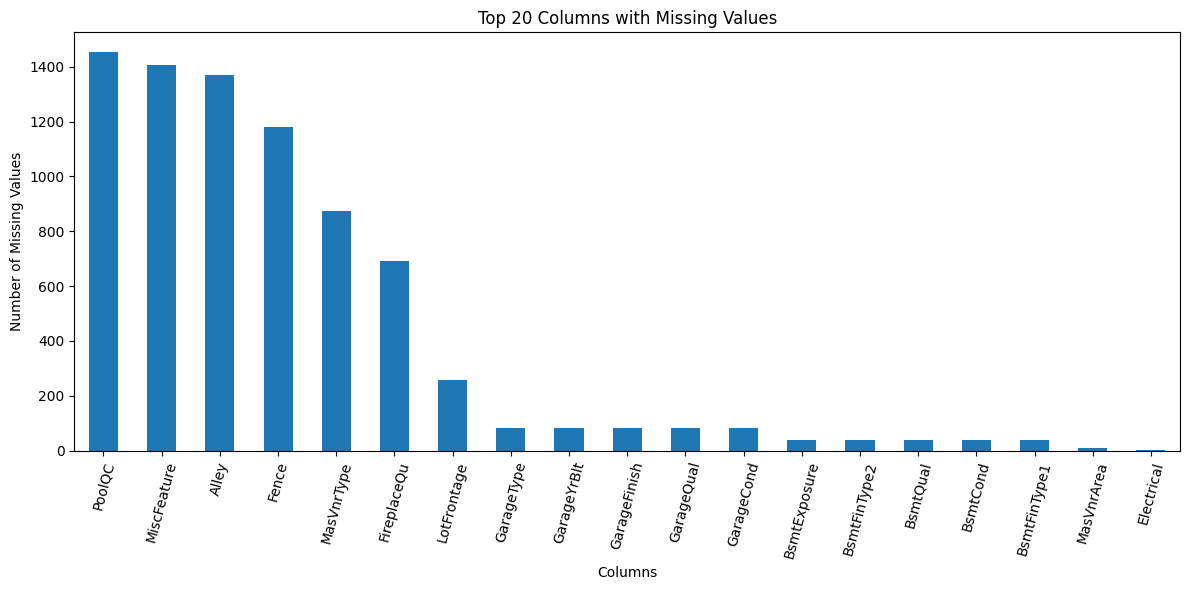

In [4]:

# Count missing values
missing_values = df.isnull().sum()

# Keep only columns with missing values
missing_values = missing_values[missing_values > 0]

# Sort in descending order
missing_values = missing_values.sort_values(ascending=False)

# Display missing values
print("Columns with Missing Values:")
print(missing_values)

# Plot top 20 columns with missing values
plt.figure(figsize=(12, 6))
missing_values.head(20).plot(kind="bar")
plt.title("Top 20 Columns with Missing Values")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()


In [5]:
# Copy the dataset
df_clean = df.copy()

# Separate numerical and categorical columns
numerical_cols = df_clean.select_dtypes(include=["int64", "float64"]).columns
categorical_cols = df_clean.select_dtypes(include=["object"]).columns

# Fill missing numerical values with median
for col in numerical_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Fill missing categorical values with mode
for col in categorical_cols:
    if df_clean[col].isnull().sum() > 0:
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

# Check missing values after cleaning
print("Missing values after cleaning:",
      df_clean.isnull().sum().sum())

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nData cleaning completed successfully!")

Missing values after cleaning: 0
Original dataset shape: (1460, 81)
Cleaned dataset shape: (1460, 81)

Data cleaning completed successfully!


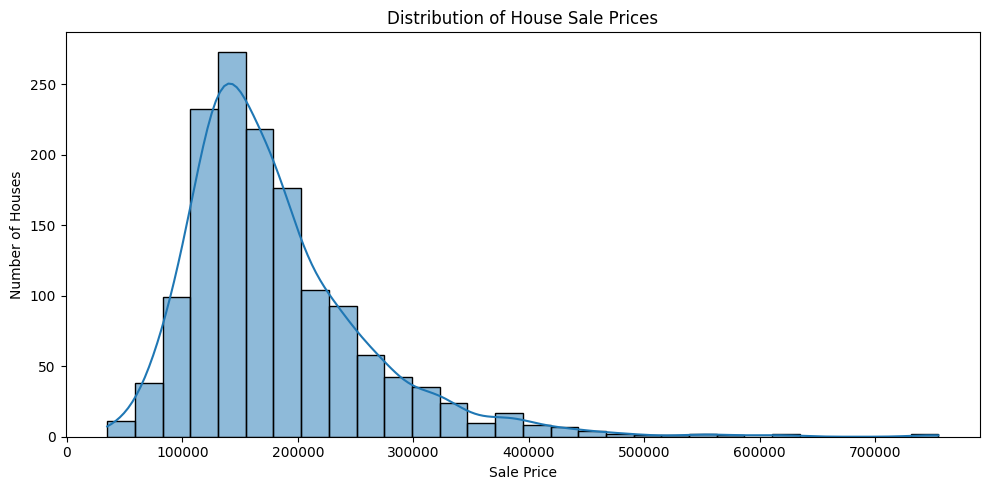

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# SalePrice Distribution
plt.figure(figsize=(10, 5))

sns.histplot(df_clean["SalePrice"], bins=30, kde=True)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price")
plt.ylabel("Number of Houses")

plt.tight_layout()
plt.show()

Correlation with SalePrice:
SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
MasVnrArea       0.472614
Fireplaces       0.466929
GarageYrBlt      0.466754
BsmtFinSF1       0.386420
LotFrontage      0.334771
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbv

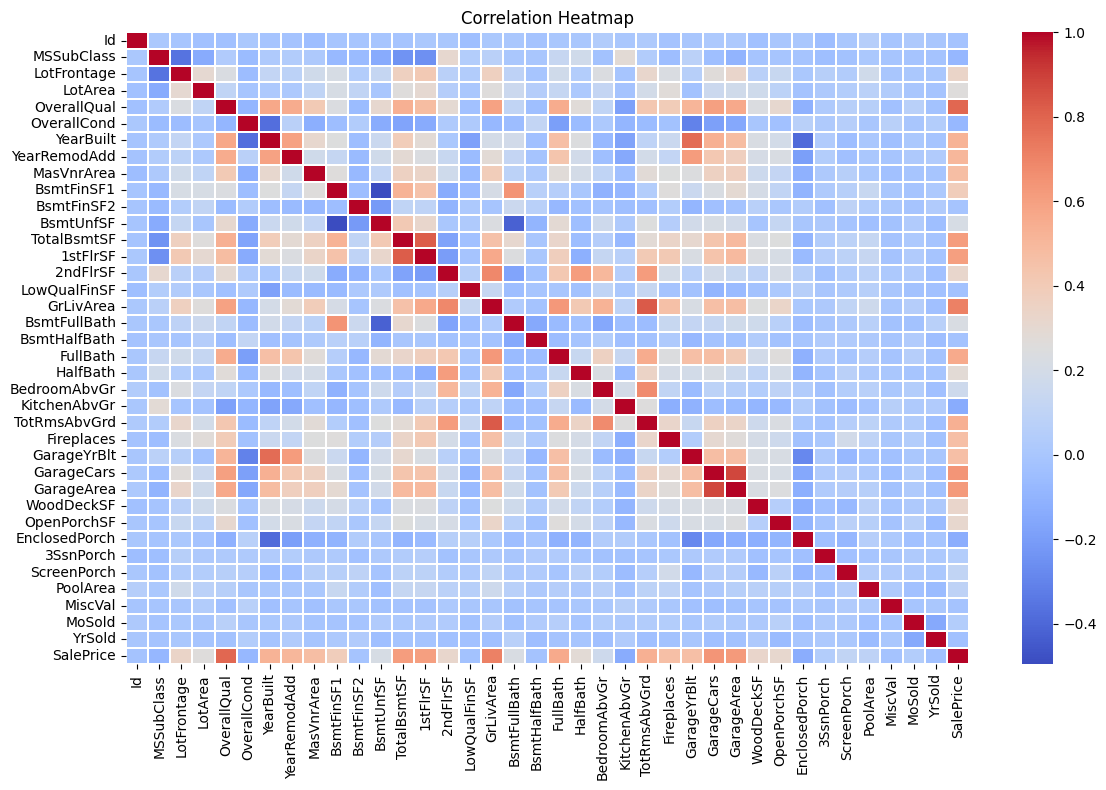

In [7]:
# Select numerical columns
numerical_df = df_clean.select_dtypes(include=["number"])

# Calculate correlation
correlation = numerical_df.corr()

# Display correlation with SalePrice
saleprice_corr = correlation["SalePrice"].sort_values(ascending=False)

print("Correlation with SalePrice:")
print(saleprice_corr)

# Plot correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    annot=False,
    linewidths=0.3
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [8]:
# Select top 10 features related to SalePrice
top_features = saleprice_corr.drop("SalePrice").head(10).index.tolist()

print("Selected Features:")
print(top_features)

# Create feature matrix (X) and target variable (y)
X = df_clean[top_features]
y = df_clean["SalePrice"]

print("\nFeature matrix shape:", X.shape)
print("Target variable shape:", y.shape)

print("\nTarget variable: SalePrice")
print("Features and target prepared successfully!")

Selected Features:
['OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'FullBath', 'TotRmsAbvGrd', 'YearBuilt', 'YearRemodAdd']

Feature matrix shape: (1460, 10)
Target variable shape: (1460,)

Target variable: SalePrice
Features and target prepared successfully!


In [9]:
from sklearn.model_selection import train_test_split

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Display dataset sizes
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTrain-test split completed successfully!")

Training Features: (1168, 10)
Testing Features: (292, 10)
Training Target: (1168,)
Testing Target: (292,)

Train-test split completed successfully!


In [10]:
from sklearn.linear_model import LinearRegression

# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Linear Regression Model trained successfully!")

Linear Regression Model trained successfully!


In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict house prices
y_pred = model.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R2 Score:", round(r2, 4))
print("R2 Score (%):", round(r2 * 100, 2), "%")

Model Evaluation Results
------------------------
Mean Absolute Error (MAE): 24774.22
Root Mean Squared Error (RMSE): 39474.54
R2 Score: 0.7968
R2 Score (%): 79.68 %


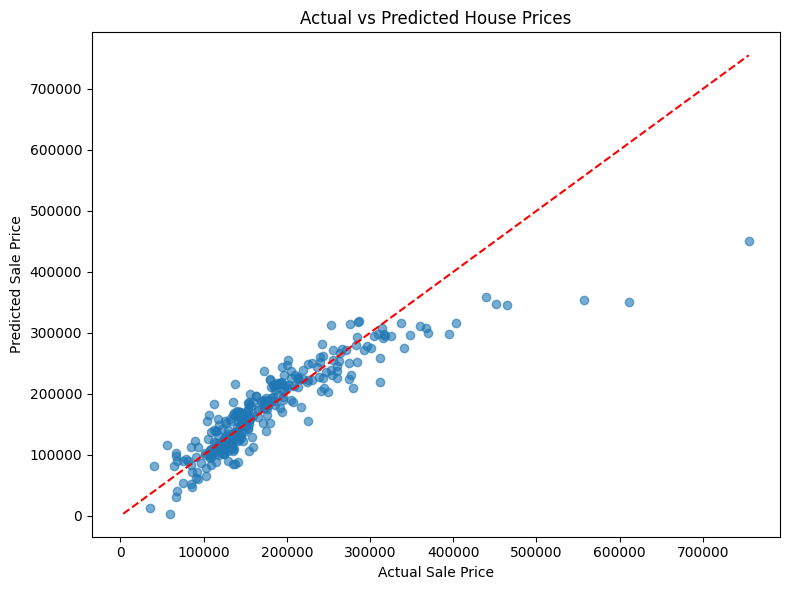

In [12]:
import matplotlib.pyplot as plt

# Compare actual and predicted prices
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

# Reference line
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    "r--"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")

plt.tight_layout()
plt.show()

In [13]:
import pandas as pd

# Create comparison table
results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

# Calculate prediction error
results["Error"] = (
    results["Actual Price"] - results["Predicted Price"]
).round(2)

# Display first 10 predictions
print(results.head(10).round(2))

   Actual Price  Predicted Price     Error
0        154500        151001.46   3498.54
1        325000        295272.84  29727.16
2        115000        113483.33   1516.67
3        159000        163469.64  -4469.64
4        315500        291359.26  24140.74
5         75500         54262.40  21237.60
6        311500        219067.52  92432.48
7        146000        166895.98 -20895.98
8         84500         53070.22  31429.78
9        135500        124541.91  10958.09


In [14]:
# House Price Prediction - Project Summary

print("=" * 45)
print("HOUSE PRICE PREDICTION - PROJECT SUMMARY")
print("=" * 45)

print("Dataset rows:", df_clean.shape[0])
print("Dataset columns:", df_clean.shape[1])
print("Selected features:", len(top_features))
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nModel: Linear Regression")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))
print("R2 Score (%):", round(r2 * 100, 2), "%")

print("\nProject completed successfully!")

HOUSE PRICE PREDICTION - PROJECT SUMMARY
Dataset rows: 1460
Dataset columns: 81
Selected features: 10
Training samples: 1168
Testing samples: 292

Model: Linear Regression
MAE: 24774.22
RMSE: 39474.54
R2 Score: 0.7968
R2 Score (%): 79.68 %

Project completed successfully!
